# Bài thực hành tổng hợp: Xây dựng mạng Neural nhận dạng chữ số viết tay 

Trong bài tập này, bạn sẽ sử dụng mạng neural để nhận dạng các chữ số viết tay từ 0 đến 9.


# Mục lục
- [ 1 - Các thư viện ](#1)
- [ 2 - Hàm kích hoạt ReLU](#2)
- [ 3 - Hàm Softmax](#3)
  - [ Bài tập 1](#ex01)
- [ 4 - Mạng Neural](#4)
  - [ 4.1 Đặt vấn đề](#4.1)
  - [ 4.2 Bộ dữ liệu](#4.2)
  - [ 4.3 Biểu diễn mô hình](#4.3)
  - [ 4.4 Triển khai mô hình bằng TensorFlow](#4.4)
  - [ 4.5 Vị trí đặt Softmax](#4.5)
    - [ Bài tập 2](#ex02)

_**LƯU Ý:** Để tránh lỗi hệ thống, bạn không nên chỉnh sửa hoặc xóa các ô không chấm điểm trong notebook này. Đồng thời, không thêm bất kỳ ô mới nào.

<a name="1"></a>
## 1 - Các thư viện

Trước tiên, hãy chạy ô bên dưới để import tất cả các thư viện mà bạn sẽ cần trong suốt bài tập này.
- [numpy](https://numpy.org/) là gói thư viện nền tảng cho tính toán khoa học với Python.
- [matplotlib](http://matplotlib.org) là thư viện phổ biến để vẽ đồ thị trong Python.
- [tensorflow](https://www.tensorflow.org/) một nền tảng phổ biến cho học máy.

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.activations import linear, relu, sigmoid
%matplotlib widget
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')

import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

from public_tests import * 

from autils import *
from lab_utils_softmax import plt_softmax
np.set_printoptions(precision=2)

<a name="2"></a>
## 2 - Hàm kích hoạt ReLU
Tuần này, một hàm kích hoạt mới đã được giới thiệu (ReLU - Rectified Linear Unit): a = max(0,z)

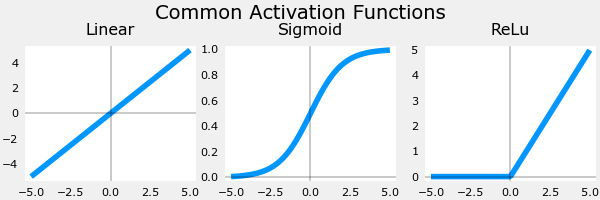

In [2]:
plt_act_trio()

<img align="right" src="./images/C2_W2_ReLu.png"     style=" width:380px; padding: 10px 20px; " >
Ví dụ từ ở bên phải minh họa một ứng dụng của ReLU. Trong ví dụ này, đặc trưng "độ nhận thức" (awareness) suy ra không phải là nhị phân mà có một dải giá trị liên tục. Hàm sigmoid phù hợp nhất cho các tình huống bật/tắt (on/off) hoặc nhị phân. ReLU cung cấp một mối quan hệ tuyến tính liên tục. Ngoài ra, nó có một dải 'tắt' (off) nơi đầu ra bằng 0.     
Đặc tính "tắt" này biến ReLU thành một hàm kích hoạt phi tuyến (Non-Linear activation). Tại sao điều này lại cần thiết? Nó cho phép nhiều đơn vị (units) cùng đóng góp vào hàm kết quả mà không làm nhiễu lẫn nhau.

<a name="3"></a>
## 3 - Hàm Softmax
Một mạng neural phân loại đa lớp (multiclass) tạo ra N đầu ra. Một đầu ra sẽ được chọn làm câu trả lời dự đoán. Ở lớp đầu ra, một vector $\mathbf{z}$ được tạo ra bởi một hàm tuyến tính, sau đó vector này được đưa vào hàm softmax. Hàm softmax chuyển đổi $\mathbf{z}$ thành một phân phối xác suất như mô tả dưới đây. Sau khi áp dụng softmax, mỗi đầu ra sẽ nằm trong khoảng từ 0 đến 1 và tổng các đầu ra sẽ bằng 1. Chúng có thể được diễn giải dưới dạng xác suất. Đầu vào cho hàm softmax càng lớn thì xác suất đầu ra tương ứng càng cao.
<center>  <img  src="./images/C2_W2_NNSoftmax.PNG" width="600" />  

Hàm softmax có thể được viết như sau:
$$a_j = \frac{e^{z_j}}{ \sum_{k=0}^{N-1}{e^{z_k} }} \tag{1}$$

Trong đó $z = \mathbf{w} \cdot \mathbf{x} + b$ và N là số lượng đặc trưng/danh mục (categories) ở lớp đầu ra.  

<a name="ex01"></a>
### Bài tập 1
Hãy cùng tạo một hàm triển khai bằng NumPy:

In [3]:
# UNQ_C1
# GRADED CELL: my_softmax

def my_softmax(z):  
    """ Softmax converts a vector of values to a probability distribution.
    Args:
      z (ndarray (N,))  : input data, N features
    Returns:
      a (ndarray (N,))  : softmax of z
    """    
    ### START CODE HERE ### 
    # Trừ giá trị lớn nhất để tránh tràn số khi tính hàm mũ.
    exp_z = np.exp(z - np.max(z))
    a = exp_z / np.sum(exp_z)
    ### END CODE HERE ### 
    return a

In [4]:
z = np.array([1., 2., 3., 4.])
a = my_softmax(z)
atf = tf.nn.softmax(z)
print(f"my_softmax(z):         {a}")
print(f"tensorflow softmax(z): {atf}")

# BEGIN UNIT TEST  
test_my_softmax(my_softmax)
# END UNIT TEST  

my_softmax(z):         [0.03 0.09 0.24 0.64]
tensorflow softmax(z): [0.03 0.09 0.24 0.64]
 All tests passed.


<details>
  <summary><font size="3" color="darkgreen"><b>Nhấn để xem gợi ý</b></font></summary>
    Một cách triển khai là sử dụng vòng lặp for: vòng lặp đầu tiên để xây dựng mẫu số, và vòng lặp thứ hai để tính toán từng đầu ra.
    
```python
def my_softmax(z):  
    N = len(z)
    a =                     # khởi tạo a gồm các số 0
    ez_sum =                # khởi tạo tổng bằng 0
    for k in range(N):      # lặp qua số lượng đầu ra
        ez_sum +=           # tính tổng exp(z[k]) để xây dựng mẫu số chung
    for j in range(N):      # lặp lại qua số lượng đầu ra
        a[j] =              # chia exp của từng đầu ra cho mẫu số
    return(a)
```


Bên dưới, hãy thay đổi giá trị của các đầu vào `z`. Hãy đặc biệt lưu ý cách hàm mũ ở tử số phóng đại những khác biệt nhỏ trong các giá trị. Cũng lưu ý rằng tổng các giá trị đầu ra luôn bằng 1.

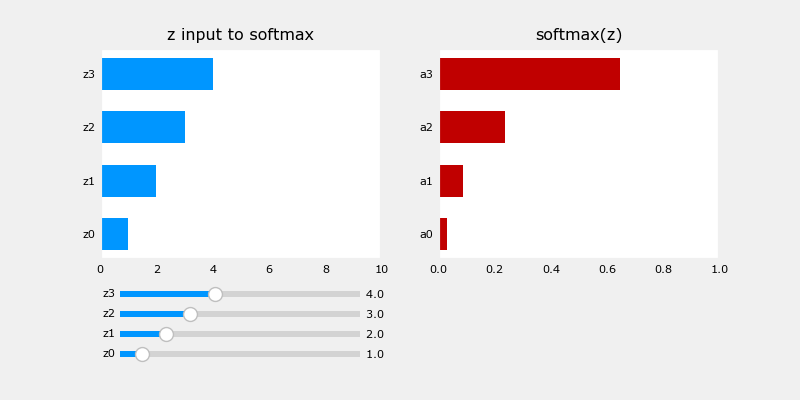

In [5]:
plt.close("all")
plt_softmax(my_softmax)

<a name="4"></a>
## 4 - Mạng Neural

Trong bài tập này bạn sẽ thực hiện mạng để phân loại đa lớp (multiclass classification), trong đó sẽ sử dụng hàm kích hoạt softmax.


<a name="4.1"></a>
### 4.1 Đặt vấn đề (Problem Statement)

Trong bài tập này, bạn sẽ sử dụng mạng neural để nhận dạng mười chữ số viết tay từ 0 đến 9. Đây là một bài toán phân loại đa lớp, trong đó một trong n lựa chọn sẽ được chọn ra. Nhận dạng chữ số viết tay tự động được ứng dụng rộng rãi - từ nhận dạng mã bưu chính (zip codes) trên phong bì thư đến nhận dạng số tiền viết trên séc ngân hàng. 


<a name="4.2"></a>
### 4.2 Bộ dữ liệu (Dataset)

Bạn sẽ bắt đầu bằng việc tải bộ dữ liệu cho tác vụ này. 
- Hàm `load_data()` dưới đây sẽ nạp dữ liệu vào các biến `X` và `y`


- Bộ dữ liệu chứa 5000 mẫu huấn luyện chữ số viết tay $^1$.  

    - Mỗi mẫu huấn luyện là một ảnh thang độ xám (grayscale) kích thước 20 pixel x 20 pixel của chữ số. 
        - Mỗi pixel được biểu diễn bởi một số thực dấu phẩy động chỉ cường độ thang độ xám tại vị trí đó. 
        - Lưới pixel 20 x 20 được “trải phẳng” (unrolled) thành một vector 400 chiều. 
        - Mỗi mẫu huấn luyện trở thành một hàng đơn lẻ trong ma trận dữ liệu `X`. 
        - Điều này cho ta một ma trận `X` có kích thước 5000 x 400, trong đó mỗi hàng là một mẫu huấn luyện của một ảnh chữ số viết tay.

$$X = 
\left(\begin{array}{cc} 
--- (x^{(1)}) --- \\
--- (x^{(2)}) --- \\
\vdots \\ 
--- (x^{(m)}) --- 
\end{array}\right)$$ 

- Phần thứ hai của tập huấn luyện là một vector kích thước 5000 x 1 chứa các nhãn cho tập huấn luyện `y`
    - `y = 0` nếu ảnh là chữ số `0`, `y = 4` nếu ảnh là chữ số `4`, v.v.

$^1$<sub> Đây là một tập con của bộ dữ liệu chữ số viết tay MNIST (http://yann.lecun.com/exdb/mnist/)</sub>

In [6]:
# load dataset
X, y = load_data()

#### 4.2.1 Quan sát các biến
Hãy làm quen hơn với bộ dữ liệu của bạn.  
- Một cách khởi đầu tốt là in từng biến ra và xem nó chứa những gì.

Đoạn code bên dưới in ra phần tử đầu tiên trong các biến `X` và `y`.  

In [7]:
print ('The first element of X is: ', X[0])

The first element of X is:  [ 0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00  0.00e+00  8.56e-06  1.94e-06 -7.37e-04
 -8.13e-03 -1.86e-02 -1.87e-02 -1.88e-02 -1.91e-02 -1.64e-02 -3.78e-03
  3.30e-04  1.28e-05  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  1.16e-04  1.20e-04 -1.40e-02 -2.85e-02  8.04e-02
  2.67e-01  2.74e-01  2.79e-01  2.74e-01  2.25e-0

In [8]:
print ('The first element of y is: ', y[0,0])
print ('The last element of y is: ', y[-1,0])

The first element of y is:  0
The last element of y is:  9


#### 4.2.2 Kiểm tra kích thước các biến

Một cách khác để làm quen với dữ liệu của bạn là xem các kích thước (dimensions) của nó. Hãy in kích thước (shape) của `X` và `y` để xem bạn có bao nhiêu mẫu huấn luyện trong bộ dữ liệu của mình.

In [9]:
print ('The shape of X is: ' + str(X.shape))
print ('The shape of y is: ' + str(y.shape))

The shape of X is: (5000, 400)
The shape of y is: (5000, 1)


#### 4.2.3 Trực quan hóa dữ liệu

Bạn sẽ bắt đầu bằng cách trực quan hóa một tập con của tập huấn luyện. 
- Trong ô bên dưới, đoạn code chọn ngẫu nhiên 64 hàng từ `X`, ánh xạ mỗi hàng trở lại thành một ảnh thang độ xám 20 pixel x 20 pixel và hiển thị các ảnh này cùng nhau. 
- Nhãn của mỗi ảnh được hiển thị ngay phía trên ảnh.

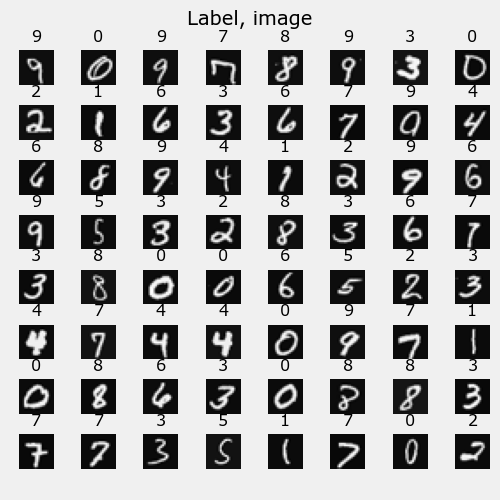

In [10]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(5,5))
fig.tight_layout(pad=0.13,rect=[0, 0.03, 1, 0.91]) #[left, bottom, right, top]

#fig.tight_layout(pad=0.5)
widgvis(fig)
for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # Display the label above the image
    ax.set_title(y[random_index,0])
    ax.set_axis_off()
    fig.suptitle("Label, image", fontsize=14)

<a name="4.3"></a>
### 4.3 Biểu diễn mô hình

Mạng neural bạn sẽ sử dụng trong bài tập này được thể hiện trong hình bên dưới. 
- Mạng gồm hai lớp dense với hàm kích hoạt ReLU, theo sau là một lớp đầu ra với hàm kích hoạt tuyến tính (linear). 
    - Hãy nhớ rằng đầu vào của chúng ta là các giá trị pixel của các ảnh chữ số.
    - Vì các ảnh có kích thước $20\times20$, điều này cho chúng ta $400$ đầu vào  
    
<img src="images/C2_W2_Assigment_NN.png" width="600" height="450">

- Các tham số có kích thước được thiết kế cho một mạng neural có $25$ đơn vị ở lớp 1, $15$ đơn vị ở lớp 2 và $10$ đơn vị đầu ra ở lớp 3, mỗi đơn vị tương ứng với một chữ số.

    - Hãy nhớ lại cách xác định kích thước của các tham số này như sau:
        - Nếu mạng có $s_{in}$ đơn vị trong một lớp và $s_{out}$ đơn vị trong lớp kế tiếp, thì 
            - $W$ sẽ có kích thước là $s_{in} \times s_{out}$.
            - $b$ sẽ là một vector có $s_{out}$ phần tử
  
    - Do đó, kích thước của `W` và `b` là: 
        - layer1: Kích thước của `W1` là (400, 25) và kích thước của `b1` là (25,)
        - layer2: Kích thước của `W2` là (25, 15) và kích thước của `b2` là (15,)
        - layer3: Kích thước của `W3` là (15, 10) và kích thước của `b3` là (10,)
>**Lưu ý:** Vector hệ số chệch (bias) `b` có thể được biểu diễn dưới dạng mảng 1-D (n,) hoặc mảng 2-D (n,1). TensorFlow sử dụng biểu diễn 1-D và bài thực hành này sẽ tuân theo quy ước đó:

<a name="4.4"></a>
### 4.4 Triển khai mô hình bằng TensorFlow

Các mô hình TensorFlow được xây dựng từng lớp một. Kích thước đầu vào của một lớp ($s_{in}$ ở trên) sẽ được tự động tính toán cho bạn. Bạn chỉ định *kích thước đầu ra* của lớp và điều này sẽ xác định kích thước đầu vào của lớp tiếp theo. Kích thước đầu vào của lớp đầu tiên được suy ra từ kích thước của dữ liệu đầu vào được chỉ định trong câu lệnh `model.fit` bên dưới. 
>**Lưu ý:** Bạn cũng có thể thêm một lớp đầu vào (input layer) chỉ định rõ kích thước đầu vào của lớp đầu tiên. Ví dụ:  
`tf.keras.Input(shape=(400,)),    #specify input shape`  
Chúng ta sẽ đưa câu lệnh đó vào đây để làm rõ cách xác định kích thước mô hình.

<a name="4.5"></a>
### 4.5 Vị trí đặt Softmax (Softmax placement)
Độ ổn định số học (numerical stability) sẽ được cải thiện nếu hàm softmax được gom chung với hàm mất mát thay vì đặt ở lớp đầu ra trong quá trình huấn luyện. Điều này ảnh hưởng đến việc *xây dựng* mô hình và *sử dụng* mô hình:  
Xây dựng mô hình:  
* Lớp Dense cuối cùng nên sử dụng hàm kích hoạt 'linear'. Điều này thực chất là không sử dụng hàm kích hoạt nào. 
* Câu lệnh `model.compile` sẽ chỉ định điều này bằng cách thêm tham số `from_logits=True`:  
`loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)`  
* Điều này không ảnh hưởng đến dạng của nhãn mục tiêu (target). Trong trường hợp của SparseCategoricalCrossentropy, mục tiêu là chữ số mong muốn từ 0 đến 9.

Sử dụng mô hình:
* Đầu ra không phải là các xác suất. Nếu muốn nhận được các xác suất đầu ra, hãy áp dụng hàm softmax.

<a name="ex02"></a>
### Bài tập 2

Bên dưới, hãy sử dụng mô hình [Sequential model](https://keras.io/guides/sequential_model/) và [Dense Layer](https://keras.io/api/layers/core_layers/dense/) của Keras với hàm kích hoạt ReLU để xây dựng mạng ba lớp như đã mô tả ở trên.

In [11]:
# UNQ_C2
# GRADED CELL: Sequential model
tf.random.set_seed(1234) # for consistent results
model = Sequential(
    [               
        ### START CODE HERE ### 
        tf.keras.Input(shape=(400,)),
        Dense(25, activation='relu', name='L1'),
        Dense(15, activation='relu', name='L2'),
        Dense(10, activation='linear', name='L3'),
        ### END CODE HERE ### 
    ], name = "my_model" 
)

In [12]:
model.summary()

Model: "my_model"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 L1 (Dense)                  (None, 25)                10025     


 L2 (Dense)                  (None, 15)                390       


 L3 (Dense)                  (None, 10)                160       


Total params: 10575 (41.31 KB)


Trainable params: 10575 (41.31 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


<details>
  <summary><font size="3" color="darkgreen"><b>Đầu ra mong đợi (Nhấn để mở rộng)</b></font></summary>
Hàm `model.summary()` hiển thị một bản tóm tắt hữu ích về mô hình. Lưu ý, tên của các lớp có thể khác nhau vì chúng được tự động tạo trừ khi tên được chỉ định cụ thể.    
    
```
Model: "my_model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
L1 (Dense)                   (None, 25)                10025     
_________________________________________________________________
L2 (Dense)                   (None, 15)                390       
_________________________________________________________________
L3 (Dense)                   (None, 10)                160       
=================================================================
Total params: 10,575
Trainable params: 10,575
Non-trainable params: 0
_________________________________________________________________
```

In [13]:
# BEGIN UNIT TEST     
test_model(model, 10, 400)
# END UNIT TEST     

All tests passed!


Số lượng tham số hiển thị trong phần tóm tắt (summary) tương ứng với số phần tử trong các mảng trọng số và bias như minh họa dưới đây.

Hãy kiểm tra sâu hơn các trọng số để xác minh rằng TensorFlow đã tạo ra các kích thước tương tự như chúng ta đã tính toán ở trên.

In [14]:
[layer1, layer2, layer3] = model.layers

In [15]:
#### Examine Weights shapes
W1,b1 = layer1.get_weights()
W2,b2 = layer2.get_weights()
W3,b3 = layer3.get_weights()
print(f"W1 shape = {W1.shape}, b1 shape = {b1.shape}")
print(f"W2 shape = {W2.shape}, b2 shape = {b2.shape}")
print(f"W3 shape = {W3.shape}, b3 shape = {b3.shape}")

W1 shape = (400, 25), b1 shape = (25,)
W2 shape = (25, 15), b2 shape = (15,)
W3 shape = (15, 10), b3 shape = (10,)


**Đầu ra mong đợi**
```
W1 shape = (400, 25), b1 shape = (25,)  
W2 shape = (25, 15), b2 shape = (15,)  
W3 shape = (15, 10), b3 shape = (10,)
```

Đoạn code sau đây:
* định nghĩa một hàm mất mát, `SparseCategoricalCrossentropy` và chỉ định rằng softmax nên được tính gộp trong phép tính hàm mất mát bằng cách thêm `from_logits=True`)
* định nghĩa một thuật toán tối ưu hóa. Một lựa chọn phổ biến là Adaptive Moment (Adam) đã được mô tả trong bài giảng.

In [16]:
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
)

history = model.fit(
    X,y,
    epochs=40
)

Epoch 1/40


  1/157 [..............................] - ETA: 1:36 - loss: 2.3001

 31/157 [====>.........................] - ETA: 0s - loss: 2.1864  

 61/157 [==========>...................] - ETA: 0s - loss: 1.9915

 92/157 [================>.............] - ETA: 0s - loss: 1.7993

...

  1/157 [..............................] - ETA: 0s - loss: 0.0356

 46/157 [=======>......................] - ETA: 0s - loss: 0.0367

 93/157 [================>.............] - ETA: 0s - loss: 0.0349

144/157 [==========================>...] - ETA: 0s - loss: 0.0354

157/157 [==============================] - 0s 1ms/step - loss: 0.0357


#### Epochs và batches
Trong câu lệnh `fit` ở trên, số lượng `epochs` được đặt là 40. Điều này chỉ định rằng toàn bộ tập dữ liệu sẽ được duyệt qua trong quá trình huấn luyện 40 lần. Trong quá trình huấn luyện, bạn thấy đầu ra mô tả tiến trình huấn luyện trông như sau:
```
Epoch 1/40
157/157 [==============================] - 0s 1ms/step - loss: 2.2770
```
Dòng đầu tiên, `Epoch 1/40`, mô tả mô hình hiện đang chạy ở epoch nào. Để đạt hiệu quả cao, tập dữ liệu huấn luyện được chia thành các 'batches' (lô dữ liệu). Kích thước mặc định của một batch trong TensorFlow là 32. Có 5000 mẫu trong tập dữ liệu của chúng ta, tương đương khoảng 157 batches. Ký hiệu ở dòng thứ hai `157/157 [====` mô tả batch nào đã được thực thi.

#### Độ mất mát (hàm chi phí - cost)
Chúng ta sẽ theo dõi tiến trình của thuật toán hạ gradient bằng cách giám sát chi phí (cost). Lý tưởng nhất là chi phí sẽ giảm khi số lần lặp của thuật toán tăng lên. TensorFlow gọi chi phí là `loss` (độ mất mát).

Ở trên, bạn đã thấy độ mất mát được hiển thị ở mỗi epoch khi `model.fit` đang thực thi. Phương thức [.fit](https://www.tensorflow.org/api_docs/python/tf/keras/Model) trả về nhiều số liệu đo lường khác nhau bao gồm cả loss. Số liệu này được lưu trữ trong biến `history` ở trên. Biến này có thể được sử dụng để khảo sát loss trên biểu đồ như minh họa dưới đây.

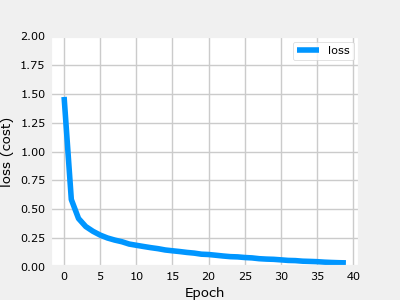

In [17]:
plot_loss_tf(history)

#### Dự đoán (Prediction)
Để đưa ra dự đoán, hãy sử dụng phương thức `predict` của Keras. Dưới đây, X[1015] chứa ảnh của một chữ số hai.

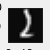

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 76ms/step


 predicting a Two: 
[[ -7.5    2.02   4.4    0.01 -11.26  -5.42  -3.94   2.09  -6.84  -5.41]]
 Largest Prediction index: 2


In [18]:
image_of_two = X[1015]
display_digit(image_of_two)

prediction = model.predict(image_of_two.reshape(1,400))  # prediction

print(f" predicting a Two: \n{prediction}")
print(f" Largest Prediction index: {np.argmax(prediction)}")

Đầu ra lớn nhất là prediction[2], cho biết chữ số được dự đoán là '2'. Nếu bài toán chỉ yêu cầu lựa chọn nhãn thì như vậy là đủ. Hãy sử dụng hàm [argmax](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html) của NumPy để chọn nhãn đó. Nếu bài toán yêu cầu một xác suất, ta cần dùng hàm softmax:

In [19]:
prediction_p = tf.nn.softmax(prediction)

print(f" predicting a Two. Probability vector: \n{prediction_p}")
print(f"Total of predictions: {np.sum(prediction_p):0.3f}")

 predicting a Two. Probability vector: 
[[5.66e-06 7.72e-02 8.29e-01 1.03e-02 1.31e-07 4.51e-05 1.97e-04 8.27e-02
  1.09e-05 4.57e-05]]
Total of predictions: 1.000


Để trả về một số nguyên đại diện cho mục tiêu được dự đoán, bạn cần lấy chỉ số (index) của xác suất lớn nhất. Điều này được thực hiện bằng hàm [argmax](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html) của NumPy.

In [20]:
yhat = np.argmax(prediction_p)

print(f"np.argmax(prediction_p): {yhat}")

np.argmax(prediction_p): 2


Hãy so sánh các dự đoán với các nhãn thực tế cho một mẫu ngẫu nhiên gồm 64 chữ số. Đoạn code này sẽ mất một chút thời gian để chạy.

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 27ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 22ms/step


1/1 [==============================] - ETA: 0s

...

1/1 [==============================] - 0s 18ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 24ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 27ms/step


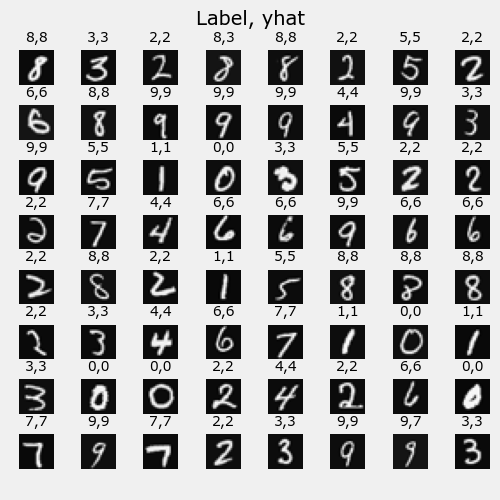

In [21]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(5,5))
fig.tight_layout(pad=0.13,rect=[0, 0.03, 1, 0.91]) #[left, bottom, right, top]
widgvis(fig)
for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # Predict using the Neural Network
    prediction = model.predict(X[random_index].reshape(1,400))
    prediction_p = tf.nn.softmax(prediction)
    yhat = np.argmax(prediction_p)
    
    # Display the label above the image
    ax.set_title(f"{y[random_index,0]},{yhat}",fontsize=10)
    ax.set_axis_off()
fig.suptitle("Label, yhat", fontsize=14)
plt.show()

Hãy cùng xem xét một số trường hợp dự đoán sai (errors). 
>Lưu ý: tăng số epoch huấn luyện có thể loại bỏ các lỗi trên tập dữ liệu này.

  1/157 [..............................] - ETA: 3s

 46/157 [=======>......................] - ETA: 0s

106/157 [===================>..........] - ETA: 0s

151/157 [===========================>..] - ETA: 0s

157/157 [==============================] - 0s 1ms/step


...

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 19ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 16ms/step


43 errors out of 5000 images


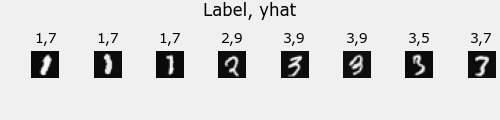

In [22]:
print( f"{display_errors(model,X,y)} errors out of {len(X)} images")

### Chúc mừng bạn!
Bạn đã xây dựng và sử dụng thành công một mạng neural dùng TensorFlow để thực hiện phân loại đa lớp (multiclass classification).

*Nguồn: Andrew Ng, Advanced Learning Algorithms, DeepLearning.AI & Standford Online.*